## EDA data set especies de pingüinos
Data set extraído de: https://www.kaggle.com/datasets/srisyra02/penguin-species-dataset

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


#### Cargando datos

In [6]:
data = pd.read_csv("../data/raw/data.csv")

data.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,41.1,18.4,195.0,3886.0,Female
1,Gentoo,Biscoe,50.0,15.4,217.0,4303.0,Male
2,Gentoo,Biscoe,50.0,15.1,220.0,4954.0,Female
3,Chinstrap,Dream,48.7,19.0,196.0,3739.0,Male
4,Adelie,Dream,39.0,17.8,187.0,3607.0,Male


## Descripción de columnas
`species`: Variable de salida (Adelie, Chinstrap, Gentoo)

`island`: Isla asociada con el pingüino

`culmen_length_mm`: Longitud del culmen en milímetros

`culmen_depth_mm`: Profundidad del culmen en milímetros

`flipper_length_mm`: Longitud de las aletas en milímetros

`body_mass_g`: Masa corporal en gramos

`sex`: (Male, Female)

In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            1000 non-null   str    
 1   island             1000 non-null   str    
 2   culmen_length_mm   990 non-null    float64
 3   culmen_depth_mm    990 non-null    float64
 4   flipper_length_mm  990 non-null    float64
 5   body_mass_g        990 non-null    float64
 6   sex                990 non-null    str    
dtypes: float64(4), str(3)
memory usage: 54.8 KB


In [8]:
data.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,990.000000,990.000000,990.000000,990.000000
mean,43.817778,17.335556,199.224242,4103.311111
std,5.309985,1.779057,13.171660,705.334794
min,32.400000,13.000000,175.000000,2830.000000
25%,39.000000,15.800000,189.000000,3586.000000
50%,43.800000,17.800000,195.000000,3882.000000
75%,48.300000,18.700000,212.000000,4587.000000
max,56.000000,21.400000,235.000000,6317.000000


In [9]:
cat_cols = data.select_dtypes(include=['str'])
cat_cols.value_counts()

species    island     sex   
Gentoo     Biscoe     Male      171
Adelie     Dream      Female    142
                      Male      132
Chinstrap  Dream      Male      130
                      Female    118
Gentoo     Biscoe     Female    114
Adelie     Torgersen  Male       91
                      Female     78
           Biscoe     Female     10
                      Male        4
Name: count, dtype: int64

### Valores nulos
No se observa una correlación específica de faltantes entre predictores. El porcentaje de entradas con valores faltantes es ~4.9%. El tipo de valores faltantes parece ser MCAR, así que procedemos a borrar las entradas con valores faltantes.

In [10]:
null_rows = data[data.isna().any(axis=1)]
print(f"De {data.shape[0]} registros, {null_rows.shape[0]} continen valores nulos")
null_rows.head()

De 1000 registros, 49 continen valores nulos


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
36,Adelie,Torgersen,39.6,17.5,NaN,3605.0,Male
38,Chinstrap,Dream,47.4,16.2,185.0,3958.0,NaN
42,Adelie,Dream,NaN,18.9,187.0,3567.0,Male
51,Gentoo,Biscoe,47.2,16.4,NaN,4792.0,Female
149,Adelie,Torgersen,38.3,18.7,195.0,NaN,Male


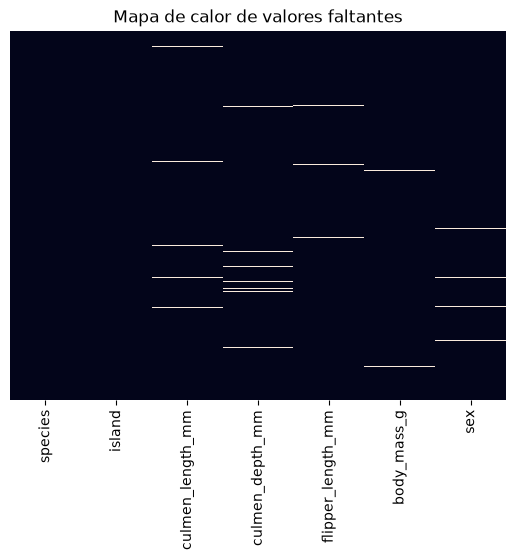

In [11]:
sns.heatmap(data.isnull(), cbar=False, yticklabels=False)

plt.title('Mapa de calor de valores faltantes')
plt.show()

In [12]:
data = data.dropna()

### Valores duplicados
No hay presencia de valores duplicados

In [13]:
dup_rows = data[data.duplicated()]
dup_rows

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex


### Analísis univariado

array([[<Axes: title={'center': 'culmen_length_mm'}>,
        <Axes: title={'center': 'culmen_depth_mm'}>],
       [<Axes: title={'center': 'flipper_length_mm'}>,
        <Axes: title={'center': 'body_mass_g'}>]], dtype=object)

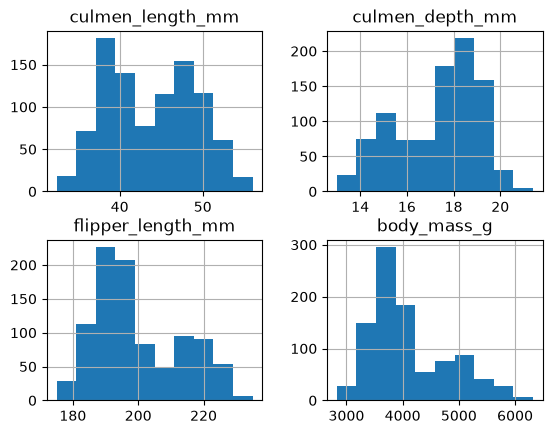

In [14]:
num_cols = data.select_dtypes(include=['float64'])

num_cols.hist()

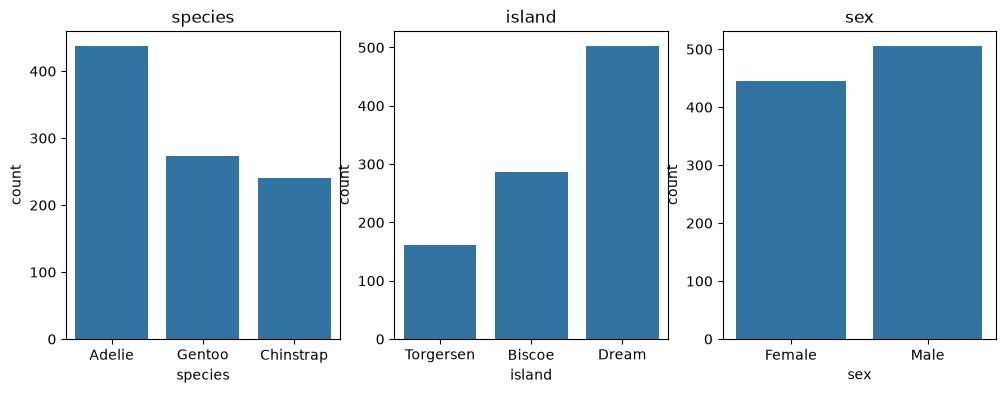

In [15]:
cat_data = data.select_dtypes(include=['str'])
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for i, ax in enumerate(ax.flat):
    col = cat_data.columns[i]
    sns.countplot(data=cat_data, x=col, ax=ax)
    ax.set_title(col)
plt.show()

### Análisis bivariado

Observaciones de variables numéricas:

- `culmen_length_mm`: La especie Adelie presenta un culmen más corto que las especies Gentoo y Chinstrap
- `culmen_depth_mm`: La especie Gentoo presenta un culmen menos profundo que las especies Adelie y Chinstrap
- `flipper_length_mm`: La especie Gentoo presenta aletas más largas que las especies Adelie y Chinstrap
- `body_mass_g`: La especie Gentoo presenta una masa corporal mayor a las otras dos especies

Podemos decir que los predictores cuantitativos afectan a la clase de salida de la siguiente manera:
- `Adelie`: Longitud de culmen entre 35 y 45mm, profundidad de culmen entre 16 a 20mm, longitud de aleta de 180 a 205mm, masa corporal de 3000 a 4500g
- `Gento`: Longitud de culmen entre 40 y 44mm, profundidad de culmen entre 5 a 17mm, longitud de aleta de 200 a 230mm, masa corporal de 4000 a 6000g
- `Chinstrap`: Longitud de culmen entre 41 y 52mm, profundidad de culmen entre 16 a 22mm, longitud de aleta de 170 a 215mm, masa corporal de 3000 a 4500g


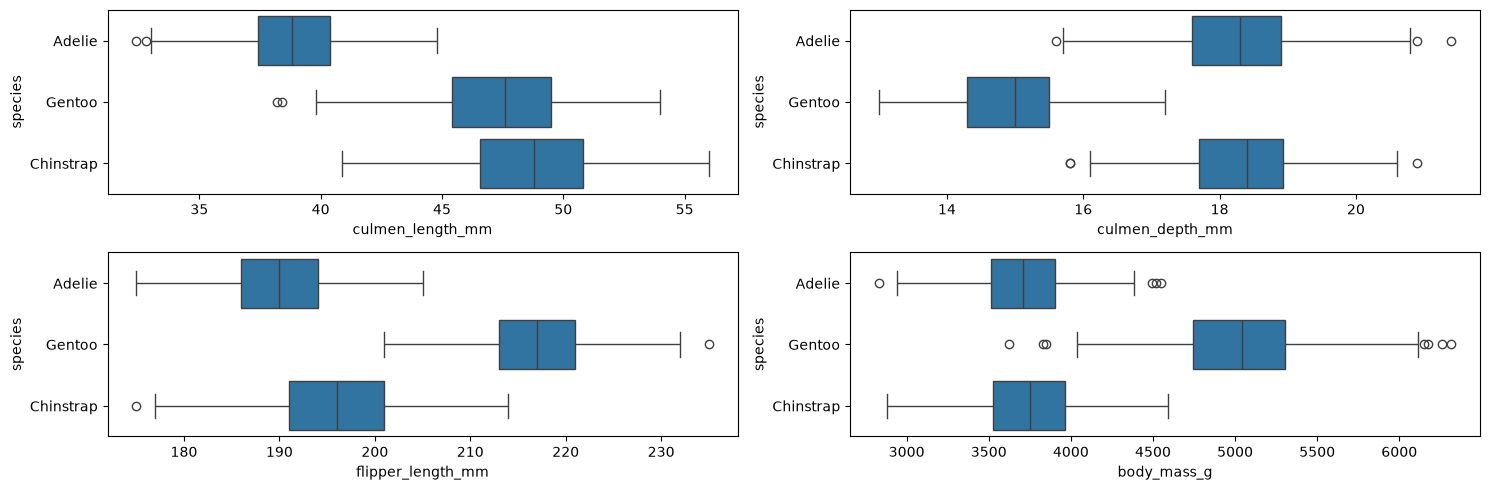

In [16]:
fig, ax = plt.subplots(2, 2, figsize=(15, 5))
for i, ax in enumerate(ax.flat):
    col = num_cols.columns[i]
    sns.boxplot(data=data, x=col, y='species', ax=ax)

plt.tight_layout()
plt.show()

Observaciones:
- `island`: La isla de Torgersen posee exclusivamente pingüinos `Adelie`, la isla Biscoe es la única isla que tiene pingüinos `Gentoo` y la isla Dream es la isla con mayor cantidad de `Adelie` y es la única que posee `Chinstrap`
- `sex`: La distribución del sexo parece estar balanceada con respecto a la cantidad de ejemplares de cada especie

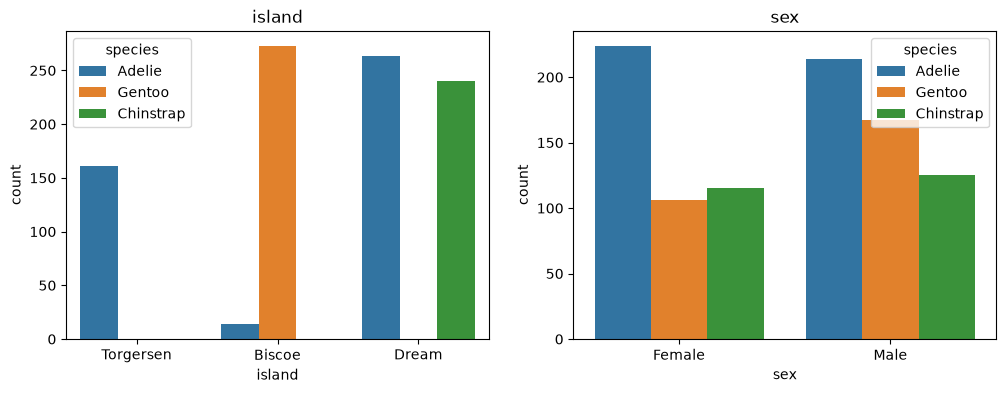

In [17]:
cat_data = cat_data.drop(columns=['species'])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, ax in enumerate(ax.flat):
    col = cat_data.columns[i]
    sns.countplot(data=data, x=col, ax=ax, hue='species')
    ax.set_title(col)
plt.show()